# 00 — Building the retrieval corpus

An internal knowledge assistant answers employee questions from company documents. Before anything
can be retrieved, mixed-format documents (Word, Excel, digital and scanned PDF, Hebrew and English)
must become clean, citable text passages — **chunks**. This notebook builds that corpus from the
original files:

| Step | Question |
|---|---|
| **1 · Convert** | How do we turn every format, including a scanned PDF, into clean Markdown? |
| **2 · Chunk** | Which chunking strategy keeps each passage on one topic, under a size cap, and labelled with its section? |
| **3 · Corpus** | How do we make retrieval evaluation harder without leaking answers? |

**Input:** the 15 documents in [`raw_data/`](https://github.com/tal-mat/knowledge-assistant/tree/main/raw_data)
(synthetic demo data of the fictional company *Tovana*). Everything else is defined in this notebook.
**Runtime:** CPU, ≈ 5–8 min on a fresh Colab runtime.

In [1]:
# ==== Setup ==================================================================
# Fresh Colab runtime -> install only what is missing:
#   * docling is PINNED: a different version can extract a table or a heading differently, and
#     then the chunks (and every later result) change.
#   * tesseract (the OCR engine for the scanned PDF) + its Hebrew model are system packages (apt).
# =============================================================================
import importlib.metadata
import importlib.util
import shutil
import subprocess
import sys

DOCLING_VERSION = "2.140.0"


def installed_version(dist: str) -> str | None:
    try:
        return importlib.metadata.version(dist)
    except importlib.metadata.PackageNotFoundError:
        return None


pip_needed = [] if installed_version("docling") == DOCLING_VERSION else [f"docling=={DOCLING_VERSION}"]
pip_needed += [p for p, mod in {"seaborn": "seaborn", "pypdfium2": "pypdfium2"}.items()
               if importlib.util.find_spec(mod) is None]
if pip_needed:
    print("Installing:", ", ".join(pip_needed), "(≈ 2–3 min) …", flush=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pip_needed], check=True)



def tesseract_langs() -> set[str]:
    if shutil.which("tesseract") is None:
        return set()
    out = subprocess.run(["tesseract", "--list-langs"], capture_output=True, text=True).stdout
    return set(out.split()[1:]) if out else set()


if not {"heb", "eng"} <= tesseract_langs():
    if shutil.which("apt-get") is None:
        raise RuntimeError("Install Tesseract OCR with the 'heb' and 'eng' language models and re-run.")
    print("Installing tesseract-ocr + Hebrew model (apt) …", flush=True)
    subprocess.run("apt-get -qq update && apt-get -qq install -y tesseract-ocr tesseract-ocr-heb > /dev/null",
                   shell=True, check=True)

TESSERACT_VERSION = subprocess.run(["tesseract", "--version"], capture_output=True, text=True).stdout.split("\n")[0]
print(f"docling {installed_version('docling')} · {TESSERACT_VERSION}")

Installing: docling==2.140.0, pypdfium2 (≈ 2–3 min) …
Installing tesseract-ocr + Hebrew model (apt) …
docling 2.140.0 · tesseract 5.3.4


In [2]:
# ==== Configuration ==========================================================
import hashlib
import html
import json
import logging
import os
import re
import statistics
import tempfile
import time
import urllib.parse
import urllib.request
import warnings
from itertools import dropwhile, groupby
from pathlib import Path
from typing import NamedTuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import HTML, Markdown, display

warnings.filterwarnings("ignore")
for name in ("docling", "docling_core", "docling_ibm_models", "huggingface_hub", "transformers"):
    logging.getLogger(name).setLevel(logging.ERROR)
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
sns.set_theme(style="whitegrid", context="notebook")

RAW_BASE = "https://raw.githubusercontent.com/tal-mat/knowledge-assistant/main/raw_data/"

# Chunk size limits (characters).
TOO_SMALL, TOO_LARGE = 100, 1500     # reported lower bound / hard upper cap per chunk
FRAGMENT_BODY_CHARS = 20             # a heading with less body than this is a stub, not a section
FIXED_SIZE, FIXED_OVERLAP = 800, 100 # sliding window for prose that is still too long
ROWS_PER_TABLE_CHUNK = 8             # oversized tables are cut every 8 rows, header repeated

# OCR: a PDF whose extracted text is shorter than this has no text layer (a scan).
OCR_EMPTY_THRESHOLD_CHARS = TOO_SMALL
OCR_LANGS, OCR_RENDER_SCALE = "heb+eng", 2.0

# Distractors may share vocabulary with real chunks, but not content.
JACCARD_CAP = 0.35


def load_hf_token() -> bool:
    """HF_TOKEN from Colab Secrets (or the environment): Docling downloads its PDF layout models from the Hub."""
    token = (os.environ.get("HF_TOKEN") or "").strip()
    if not token:
        try:
            from google.colab import userdata  # type: ignore
            token = (userdata.get("HF_TOKEN") or "").strip()
        except Exception:
            token = ""
    if token:
        os.environ["HF_TOKEN"] = os.environ["HUGGING_FACE_HUB_TOKEN"] = token
    return bool(token)


HF_TOKEN_SET = load_hf_token()


def sha256(raw: bytes) -> str:
    return hashlib.sha256(raw).hexdigest()


def _field(value) -> str:
    """Render one metadata value; missing values stay visible as an em dash."""
    if value is None or value == "":
        return "<span style='color:#8b97a3'>—</span>"
    return html.escape(str(value))


def render_chunk(chunk: dict, *, n: int | None = None, n_total: int | None = None,
                     leakage: str = "", brief: bool = False) -> str:
    """One passage as a card. `brief` keeps a one-line header so a long corpus stays scannable."""
    kind = "distractor" if chunk.get("strategy") == "synthetic" else "real"
    accent = "#E45756" if kind == "distractor" else "#4C78A8"
    label = html.escape(chunk.get("chunk_id", ""))
    if n is not None:
        label = f"{n}" + (f" / {n_total}" if n_total else "") + " · " + label
    if brief:
        bits = []
        if chunk.get("topic"):
            bits.append(str(chunk["topic"]))
        if chunk.get("language_hint"):
            bits.append(str(chunk["language_hint"]))
        if chunk.get("source_file"):
            bits.append(str(chunk["source_file"]))
        if chunk.get("section"):
            bits.append(str(chunk["section"]))
        if chunk.get("page") is not None:
            bits.append(f"p. {chunk['page']}")
        bits.append(f"{chunk.get('char_count', len(chunk.get('text') or ''))} chars")
        meta = ("<div style='color:#5c6b7a;font-size:0.82rem;margin-top:0.2rem'>"
                + html.escape(" · ".join(bits)) + "</div>")
    else:
        preferred = ["chunk_id", "strategy", "topic", "language_hint", "title", "section", "context",
                     "doc_id", "source_file", "source_format", "page", "char_count", "source_sha256"]
        keys = [k for k in preferred if k in chunk] + [k for k in chunk if k not in preferred and k != "text"]
        rows = []
        for key in keys:
            rows.append(
                "<div style='display:grid;grid-template-columns:9.2rem 1fr;gap:0.15rem 0.75rem;"
                "padding:0.16rem 0;border-bottom:1px solid #eef2f6'>"
                f"<div style='color:#5c6b7a;font-size:0.78rem'>{html.escape(key)}</div>"
                "<div style='font-family:ui-monospace,monospace;font-size:0.82rem;word-break:break-word'>"
                f"{_field(chunk.get(key))}</div></div>"
            )
        meta = f"<div style='margin-top:0.4rem'>{''.join(rows)}</div>"
    return (
        f"<article style='border:1px solid #d5dee8;border-left:4px solid {accent};border-radius:8px;"
        "padding:0.8rem 1rem;margin:0.65rem 0;background:#fff;max-width:54rem'>"
        "<div style='display:flex;justify-content:space-between;gap:1rem;align-items:baseline'>"
        f"<div style='font-weight:600'>{label}</div>"
        f"<div style='font-size:0.72rem;letter-spacing:0.04em;text-transform:uppercase;color:{accent}'>{kind}</div>"
        "</div>"
        f"{meta}"
        "<div dir='auto' style='margin-top:0.7rem;padding:0.7rem 0.85rem;background:#f6f8fb;border-radius:6px;"
        f"white-space:pre-wrap;line-height:1.45'>{_field(chunk.get('text'))}</div>"
        f"{leakage}</article>"
    )


CAP = "<p style='color:#5c6b7a;margin:0 0 0.4rem'>"  # caption style under example headings


def show_md(text: str) -> None:
    """Render Markdown built from computed values (no number in the text is typed by hand)."""
    display(Markdown(text))


print(f"HF token: {'set' if HF_TOKEN_SET else 'not set (optional — add HF_TOKEN in Colab Secrets)'}")

HF token: set


## Data

15 documents: 7 Word, 3 Excel, 4 digital PDF and 1 scanned PDF, in Hebrew and English. Each file
is verified against its SHA-256; the first 12 hex characters become the document id, so every chunk id
is tied to the exact bytes of its source.

In [3]:
# ==== Download and verify the documents ======================================
RAW_SHA256 = {
    "Approved_Software_Catalog.xlsx": "195aafee3696dd3749423faf65218d539053000d4d42014811a52d7a89cd0cb3",
    "CloudFix_Vendor_Guidelines.pdf": "347f1913991f9e4e28175430b0fd99667cf5d3f73595686b9b3eccc625853f33",
    "FAQ עובדים חדשים.docx": "c5cce790e224382bd3d642c39e34967891ce1496ffef2a665e696ce2e031d813",
    "Password_and_MFA_Policy.pdf": "14c44a5a9153a4160ea0610a4e732aadb0ae08ed9d703e3ec938deb39ae2a94a",
    "SCAN_20230215_0931.pdf": "42cda623f0309caa4f81026de5b20e147c265bd7c94786066a94bda2825d6f95",
    "SLA_קריאות_שירות.xlsx": "b3fe9199008b070d32c1c341802269e3a666f2558a16d803088dc3d0b7cfb2bd",
    "Travel_Policy_2025.docx": "d21fafd760ecee22bad1904fcd5111f9644c8c60b67923652a6dd5b17861f860",
    "VPN Setup Guide.docx": "38d3019d10bd541ca02ff7c10e35e14fdb46c0141004c8449e1cd38651e217d7",
    "מדיניות חופשה שנתית.docx": "1486073f4bb2e128ff62822bd010012b812a746c27ae238ea1d9e0a884775adb",
    "מדיניות עבודה היברידית 2025.docx": "0a3104f246cc46dd73193fd5f6b6332d95ba14532e71cb02849d24fd9ec8eff3",
    "מדיניות שימוש בכלי AI.docx": "17fee73c152f0c4a3fb33533dc8307956f1f2501240bf2a750e9dedc7ed6824d",
    "נוהל החזרי הוצאות v4.2.pdf": "43fb6ce705a37365e9a09f2c70388a3d56e9a3a242c963aabe367ac2b510b1d7",
    "נוהל_ימי_מחלה.docx": "38fe3ee78cc13755d71e8f8115cab291d0d396e94b1767999f9550daa88a17cc",
    "סמכויות אישור רכש.pdf": "d7796fb6f7cfcb1f39e69eaab7c4f6d6ff6cbd564d73fbf75a5c1bfad865ad59",
    "קטלוג ציוד מחשוב 2026.xlsx": "ad3f2765b0da040c2ba1eb2856d015b8517c01eb157412b50eaa3c75f40a22fc",
}

WORK = Path(tempfile.mkdtemp(prefix="raw_"))  # Docling needs file paths
rows = []
for name, expected in RAW_SHA256.items():
    data = urllib.request.urlopen(RAW_BASE + urllib.parse.quote(name), timeout=60).read()
    assert sha256(data) == expected, f"{name}: file differs from the original"
    (WORK / name).write_bytes(data)
    rows.append({"file": name, "format": Path(name).suffix[1:], "kB": round(len(data) / 1024, 1), "doc_id": expected[:12]})
display(pd.DataFrame(rows))

,file,format,kB,doc_id
0,Approved_Software_Catalog.xlsx,xlsx,7.3,195aafee3696
1,CloudFix_Vendor_Guidelines.pdf,pdf,21.1,347f1913991f
2,FAQ עובדים חדשים.docx,docx,36.4,c5cce790e224
3,Password_and_MFA_Policy.pdf,pdf,30.4,14c44a5a9153
4,SCAN_20230215_0931.pdf,pdf,28.8,42cda623f030
5,SLA_קריאות_שירות.xlsx,xlsx,6.4,b3fe9199008b
6,Travel_Policy_2025.docx,docx,36.5,d21fafd760ec
7,VPN Setup Guide.docx,docx,36.5,38d3019d10bd
8,מדיניות חופשה שנתית.docx,docx,38.0,1486073f4bb2
9,מדיניות עבודה היברידית 2025.docx,docx,36.4,0a3104f246cc


## 1 · Convert documents to Markdown

[Docling](https://github.com/docling-project/docling) parses Word, Excel and PDF into one document
model and exports Markdown (headings, pipe tables). Three issues are handled on top of it:

1. **Scanned PDF** — no text layer, so Docling returns almost nothing. Pages are then rendered and
   read with **Tesseract OCR** (Hebrew + English).
2. **Citations** — PDF pages are marked `<!-- page N -->` so an answer can cite its page.
3. **Noise** — invisible bidi marks and icon-font glyphs are stripped, tables normalised, and
   visually-ordered Hebrew lines in PDFs are put back into reading order.

In [4]:
# ==== Markdown cleanup (bidi / private-use noise, tables, Hebrew order) ======
_BIDI = re.compile("[\u200e\u200f\u202a-\u202e\u2066-\u2069]")  # invisible direction marks
_HEB = re.compile(r"[\u0590-\u05ff]")
_PUA = re.compile(r"[\ue000-\uf8ff]")                             # private-use glyphs (icon fonts)
_TROW = re.compile(r"^\|(.+)\|\s*$")
_SEP_CELL = re.compile(r"^:?-{3,}:?$")
_BULLETS = str.maketrans({"\uf0b7": "•", "\uf0a7": "•", "\uf076": "•", "\uf0d8": "•"})  # Symbol-font bullets


def _rtl(text: str, *, aggressive: bool) -> str:
    """Reorder one visual-order Hebrew fragment into reading order.

    PDF text layers often store Hebrew left-to-right. "Selective" mode only flips lines that show
    the tell-tale sign of reversal (punctuation or a bullet on the wrong end); headings, numbered
    items and lines without Hebrew are left alone.
    """
    stripped = text.strip()
    if (not _HEB.search(text) or not stripped or stripped.startswith("#")
            or "##" in text or re.match(r"^\d+\.\s", stripped)):
        return text
    tokens = text.split()
    if len(tokens) >= 2 and (aggressive or re.match(r"^[.,:;•]", tokens[0]) or tokens[-1].endswith("•")):
        return " ".join(reversed(tokens))
    return text


def _is_separator(cells: list[str]) -> bool:
    return all(_SEP_CELL.match(c or "---") for c in cells)


def _render_table(block: list[str], *, fix_rtl: bool, aggressive: bool) -> list[str]:
    """Re-emit one pipe table with a uniform width; single-column 'banner' tables become plain text."""
    rows = [[c.strip() for c in _TROW.match(ln.rstrip()).group(1).split("|")] for ln in block]
    if fix_rtl:
        rows = [r if _is_separator(r) else [_rtl(c, aggressive=aggressive) for c in r] for r in rows]
    data = [r for r in rows if not _is_separator(r)]
    if data and all(not any(c.strip() for c in r[1:]) for r in data):
        return [r[0] for r in data if r and r[0].strip()]
    width = max(len(r) for r in rows)
    out = []
    for row in rows:
        padded = row + [""] * (width - len(row))
        cells = ["---"] * width if _is_separator(row) else [c.replace("|", r"\|") for c in padded]
        out.append("| " + " | ".join(cells) + " |")
    return out


def sanitize_markdown(text: str, *, fix_rtl: bool = False, rtl_aggressive: bool = False) -> str:
    """Strip bidi/private-use noise, normalise pipe tables, optionally fix Hebrew order."""
    text = _PUA.sub("", html.unescape(_BIDI.sub("", text)).translate(_BULLETS))
    text = re.sub(r"(?m)^[\-\*]\s*•\s*", "• ", text)  # "- •" (list item + glyph bullet) -> one bullet
    out: list[str] = []
    for is_table, group in groupby(text.splitlines(), key=lambda ln: bool(_TROW.match(ln.rstrip()))):
        block = list(group)
        if is_table:
            out.extend(_render_table(block, fix_rtl=fix_rtl, aggressive=rtl_aggressive))
        else:
            out.extend(_rtl(ln, aggressive=rtl_aggressive) if fix_rtl else ln for ln in block)
    return "\n".join(out)


# ---- page markers: `<!-- page N -->` before each PDF page, so chunks can cite a page ----
PAGE_BREAK_PLACEHOLDER = "<!--PAGE_BREAK-->"
_EXISTING_PAGE = re.compile(r"<!--\s*page\s+\d+\s*-->", re.IGNORECASE)


def page_marker(n: int) -> str:
    return f"<!-- page {n} -->"


def apply_page_markers(text: str, *, page_count: int | None) -> str:
    """Turn Docling's page-break placeholders into numbered markers (OCR output already has them)."""
    text = (text or "").strip()
    if _EXISTING_PAGE.search(text):
        return text
    if PAGE_BREAK_PLACEHOLDER in text:
        parts = [p.strip() for p in text.split(PAGE_BREAK_PLACEHOLDER) if p.strip()]
        return "\n\n".join(f"{page_marker(i)}\n\n{p}" for i, p in enumerate(parts, 1)) if parts else page_marker(1)
    if not text:
        return page_marker(1) if (page_count or 0) >= 1 else ""
    return f"{page_marker(1)}\n\n{text}"

In [5]:
# ==== Docling conversion with an OCR fallback ================================
import pypdfium2 as pdfium
from docling.backend.pypdfium2_backend import PyPdfiumDocumentBackend
from docling.datamodel.base_models import InputFormat
from docling.datamodel.pipeline_options import PdfPipelineOptions
from docling.document_converter import DocumentConverter, PdfFormatOption
from docling.pipeline.standard_pdf_pipeline import StandardPdfPipeline


def make_converter() -> DocumentConverter:
    """Docling with PDF table-structure recognition on and Docling's own OCR off.

    OCR is handled explicitly below (Tesseract, Hebrew-capable, pinned models) and only for files
    without a text layer, so digital PDFs are never re-read from pixels.
    """
    opts = PdfPipelineOptions()
    opts.do_table_structure, opts.do_ocr = True, False
    return DocumentConverter(
        allowed_formats=[InputFormat.DOCX, InputFormat.XLSX, InputFormat.PDF],
        format_options={InputFormat.PDF: PdfFormatOption(
            pipeline_cls=StandardPdfPipeline, backend=PyPdfiumDocumentBackend, pipeline_options=opts)},
    )


def ocr_pdf(path: Path) -> tuple[str, int]:
    """Render every page (grayscale, 2x) and OCR it with Tesseract; returns (markdown, page_count)."""
    blocks: list[str] = []
    pdf = pdfium.PdfDocument(path)
    try:
        page_count = len(pdf)
        with tempfile.TemporaryDirectory() as tmp:
            for i, page in enumerate(pdf):
                img = Path(tmp) / f"p{i}.png"
                page.render(scale=OCR_RENDER_SCALE).to_pil().convert("L").save(img)
                done = subprocess.run(["tesseract", str(img), "stdout", "-l", OCR_LANGS],
                                      capture_output=True, check=False)
                if done.returncode != 0:
                    raise RuntimeError(f"Tesseract failed on page {i + 1}: {done.stderr.decode(errors='replace')}")
                if text := done.stdout.decode("utf-8", "replace").strip():
                    blocks.append(f"{page_marker(i + 1)}\n\n{text}")
    finally:
        pdf.close()
    return _BIDI.sub("", "\n\n".join(blocks)), page_count


def to_markdown(converter: DocumentConverter, path: Path) -> tuple[str, str, int | None]:
    """One file -> (markdown body, method 'docling'|'ocr', page_count)."""
    result, is_pdf = converter.convert(path), path.suffix.lower() == ".pdf"
    page_count = int(result.document.num_pages()) if is_pdf else None
    md_text = (result.document.export_to_markdown(
        page_break_placeholder=PAGE_BREAK_PLACEHOLDER if is_pdf else None) or "").strip()
    method = "docling"
    if is_pdf and len(md_text) < OCR_EMPTY_THRESHOLD_CHARS:  # no text layer -> scanned page images
        ocr_text, pages = ocr_pdf(path)
        if len(ocr_text.strip()) > len(md_text):
            md_text, method, page_count = ocr_text.strip(), "ocr", pages
    if is_pdf:
        md_text = apply_page_markers(md_text, page_count=page_count)
    # Hebrew order is fixed only for PDFs (Word/Excel store logical order); OCR stays non-aggressive.
    return sanitize_markdown(md_text, fix_rtl=is_pdf, rtl_aggressive=False) + "\n", method, page_count



CONVERTER = make_converter()
DOCS: dict[str, dict] = {}   # file name -> {"meta": ..., "body": markdown}
conv_rows = []
for name in RAW_SHA256:
    path = WORK / name
    try:
        body, method, pages = to_markdown(CONVERTER, path)
        error = ""
    except Exception as e:  # one bad file must not hide the status of the others
        body, method, pages, error = "", "error", None, f"{type(e).__name__}: {e}"[:200]
    DOCS[name] = {"meta": {"source": name, "source_type": path.suffix[1:].lower(), "title": path.stem,
                           "method": method, "page_count": pages, "sha256": sha256(path.read_bytes())},
                  "body": body}
    conv_rows.append({"file": name, "format": path.suffix[1:], "method": method, "pages": pages,
                      "chars": len(body.strip()), "headings": len(re.findall(r"(?m)^#{1,3}\s", body)),
                      "table rows": len(re.findall(r"(?m)^\|.*\|\s*$", body)), "error": error})
CONV_DF = pd.DataFrame(conv_rows)
shown = CONV_DF.assign(pages=CONV_DF["pages"].map(lambda p: "—" if pd.isna(p) else int(p)))
display(shown.drop(columns="error") if not CONV_DF["error"].any() else shown)

,file,format,method,pages,chars,headings,table rows
0,Approved_Software_Catalog.xlsx,xlsx,docling,—,2979,0,27
1,CloudFix_Vendor_Guidelines.pdf,pdf,docling,1,559,5,0
2,FAQ עובדים חדשים.docx,docx,docling,—,624,1,0
3,Password_and_MFA_Policy.pdf,pdf,docling,1,660,4,0
4,SCAN_20230215_0931.pdf,pdf,ocr,1,272,0,0
5,SLA_קריאות_שירות.xlsx,xlsx,docling,—,813,0,13
6,Travel_Policy_2025.docx,docx,docling,—,784,6,7
7,VPN Setup Guide.docx,docx,docling,—,959,4,5
8,מדיניות חופשה שנתית.docx,docx,docling,—,906,8,5
9,מדיניות עבודה היברידית 2025.docx,docx,docling,—,560,5,0


In [6]:
# ==== Conversion — results ===================================================
ocr_files = CONV_DF.loc[CONV_DF['method'] == 'ocr', 'file'].tolist()
by_fmt = CONV_DF.groupby('format')['chars'].agg(['count', 'median', 'max']).astype(int)
no_head = CONV_DF.loc[CONV_DF['headings'] == 0, 'file'].tolist()
show_md(
    f"- All **{int((CONV_DF['chars'] > 0).sum())}/{len(CONV_DF)}** documents produce Markdown; OCR is needed only for "
    f"{', '.join(f'`{f}`' for f in ocr_files) or 'none'}.\n"
    "- Size by format (chars): "
    + "; ".join(f"{f}: median {r['median']}, max {r['max']}" for f, r in by_fmt.iterrows()) + ".\n"
    "- Documents with headings, by format: "
    + "; ".join(f"{f}: {int((g['headings'] > 0).sum())}/{len(g)}" for f, g in CONV_DF.groupby('format'))
    + f". Documents without any heading ({', '.join(f'`{f}`' for f in no_head)}) are tables or flat text, "
    "so a chunker cannot rely on headings alone."
)

EXAMPLE = "מדיניות עבודה היברידית 2025.docx"
# The whole converted document, shown in the same card format as the chunks below
doc_meta = DOCS[EXAMPLE]['meta']
mock_chunk = {
    "chunk_id": doc_meta.get("sha256", "")[:12],
    "text": DOCS[EXAMPLE]['body'].strip(),
    "strategy": "full_document",
    "source_file": doc_meta["source"],
    "source_format": doc_meta["source_type"],
    "title": doc_meta["title"],
    "section": "(Full Body)",
    "page": None,
    "char_count": len(DOCS[EXAMPLE]['body'])
}

show_md("### Example — one converted document")
display(HTML(f"{CAP}The full Markdown of one Word document after conversion and cleanup.</p>" + render_chunk(mock_chunk)))

- All **15/15** documents produce Markdown; OCR is needed only for `SCAN_20230215_0931.pdf`.
- Size by format (chars): docx: median 624, max 959; pdf: median 531, max 660; xlsx: median 813, max 2979.
- Documents with headings, by format: docx: 7/7; pdf: 4/5; xlsx: 0/3. Documents without any heading (`Approved_Software_Catalog.xlsx`, `SCAN_20230215_0931.pdf`, `SLA_קריאות_שירות.xlsx`, `קטלוג ציוד מחשוב 2026.xlsx`) are tables or flat text, so a chunker cannot rely on headings alone.

### Example — one converted document

## 2 · Chunking strategy

A good chunk holds **one topic**, is **small enough** to rank sharply, and carries the **section and
page** it came from. Four strategies are compared on all 15 documents:

| Strategy | Idea |
|---|---|
| **fixed** | windows of `FIXED_SIZE` chars with `FIXED_OVERLAP` overlap |
| **heading** | one chunk per `#`/`##`/`###` section |
| **marker** | split on `<!-- page N -->` / `## Sheet:` markers |
| **hybrid** | heading sections → fold heading-only stubs forward → split only sections above `TOO_LARGE` (tables every `ROWS_PER_TABLE_CHUNK` rows with the header repeated, prose in fixed windows) |

**Selection criteria:** every document is covered, no chunk exceeds `TOO_LARGE`, and every chunk's text
matches its section label (`label_ok`). Among strategies that pass, prefer more chunks with a section label.

Chunk ids are `{doc_id}-{i:03d}`. `text` stays clean for citation; `context` (`title › section`) is
stored separately and prepended only when embedding.

In [7]:
# ==== The four chunking strategies ===========================================
_HEADING = re.compile(r"(?m)^#{1,3}\s+(.+)$")
_HEADING_LINE = re.compile(r"#{1,3}\s")
_TABLE_ROW = re.compile(r"^\|.*\|\s*$")
_TABLE_SEP = re.compile(r"^\|[-: |]+\|\s*$")
_PAGE = re.compile(r"<!--\s*page\s+(\d+)\s*-->", re.IGNORECASE)
_SHEET = re.compile(r"(?m)^##\s+Sheet:\s*(.+)$")


def _chunk(meta: dict, cid: str, text: str, strategy: str, section=None, page=None) -> dict:
    return {"chunk_id": cid, "text": text, "strategy": strategy, "source_file": meta["source"],
            "source_format": meta["source_type"], "title": meta["title"], "section": section, "page": page}


def chunk_fixed(meta: dict, body: str) -> list[dict]:
    """Baseline: overlapping character windows, blind to structure."""
    text, out, start = body.strip(), [], 0
    while text and start < len(text):
        end = min(len(text), start + FIXED_SIZE)
        if piece := text[start:end].strip():
            out.append(_chunk(meta, f"fixed-{len(out)}", piece, "fixed"))
        if end >= len(text):
            break
        start += FIXED_SIZE - FIXED_OVERLAP
    return out


def chunk_by_heading(meta: dict, body: str) -> list[dict]:
    """Baseline: one chunk per heading section (plus the preamble before the first heading)."""
    matches = list(_HEADING.finditer(body))
    if not matches:
        return [_chunk(meta, "heading-0", body.strip(), "heading")] if body.strip() else []
    out = []
    if preamble := body[: matches[0].start()].strip():
        out.append(_chunk(meta, "heading-preamble", preamble, "heading", section="(preamble)"))
    for i, m in enumerate(matches):
        end = matches[i + 1].start() if i + 1 < len(matches) else len(body)
        if piece := body[m.start():end].strip():
            out.append(_chunk(meta, f"heading-{i}", piece, "heading", section=m.group(1).strip()))
    return out


def chunk_by_marker(meta: dict, body: str) -> list[dict]:
    """Baseline: split on page markers (PDF) or sheet markers (Excel); nothing to split on -> nothing."""
    pages, sheets = list(_PAGE.finditer(body)), list(_SHEET.finditer(body))
    if pages:
        marks, kind = [(m.start(), m.end(), int(m.group(1)), None) for m in pages], "page"
    elif sheets:
        marks, kind = [(m.start(), m.start(), None, m.group(1).strip()) for m in sheets], "sheet"
    else:
        return []
    out = []
    for i, (start, content_start, page, sheet) in enumerate(marks):
        end = marks[i + 1][0] if i + 1 < len(marks) else len(body)
        if piece := body[content_start:end].strip():
            out.append(_chunk(meta, f"{kind}-{i}", piece, kind, section=sheet, page=page))
    return out


# ---- hybrid (the production chunker, unchanged from the pipeline) ----
class _Draft(NamedTuple):
    section: str | None
    text: str     # still contains page markers
    page: int | None


def normalize_label(label: str) -> str:
    """Fold underscores, years and parentheses so "X_2025" and "X" count as one label."""
    text = re.sub(r"\([^)]*\)|\b20\d{2}\b", " ", label.replace("_", " "))
    return " ".join(text.split()).casefold()


def context_prefix(title: str, section: str | None) -> str:
    """`title › section`, or the longer label alone when one repeats the other."""
    title = title.strip()
    if not section or section == "(preamble)":
        return title
    section = section.strip()
    nt, ns = normalize_label(title), normalize_label(section)
    if nt == ns or (nt and ns and (nt in ns or ns in nt)):
        return max(title, section, key=len)
    return f"{title} › {section}"


def citation_page(text: str) -> tuple[str, int | None]:
    """(text without page markers, first page number in it)."""
    m = _PAGE.search(text)
    kept = "\n".join(ln for ln in text.splitlines() if not _PAGE.fullmatch(ln.strip()))
    return re.sub(r"\n{3,}", "\n\n", kept).strip(), int(m.group(1)) if m else None


def _sections(body: str) -> list[_Draft]:
    heads = [(m.group(1).strip(), m.start()) for m in _HEADING.finditer(body)]
    cuts = [("(preamble)" if heads else None, 0), *heads, (None, len(body))]
    marks = [(m.start(), int(m.group(1))) for m in _PAGE.finditer(body)]
    return [_Draft(section, text, next((p for pos, p in reversed(marks) if pos <= start), None))
            for (section, start), (_, end) in zip(cuts, cuts[1:])
            if (text := body[start:end].strip())]


def _merge(drafts: list[_Draft]) -> list[_Draft]:
    """A heading with (almost) no body answers nothing alone: fold it forward (the last one backward)."""
    def stub(d: _Draft) -> bool:
        body = "\n".join(dropwhile(_HEADING_LINE.match, d.text.strip().splitlines()))
        return len(body.strip()) < FRAGMENT_BODY_CHARS

    def join(a: _Draft, b: _Draft, section: str | None) -> _Draft:
        return _Draft(section, f"{a.text.rstrip()}\n\n{b.text.lstrip()}", a.page if a.page is not None else b.page)

    out: list[_Draft] = []
    carry: _Draft | None = None
    for d in drafts:
        d = join(carry, d, d.section or carry.section) if carry else d
        carry = d if stub(d) else None
        out += [] if carry else [d]
    if carry and out:
        prev = out.pop()
        carry = join(prev, carry, prev.section or carry.section)
    return out + ([carry] if carry else [])


def _table_pieces(lines: list[str]) -> list[str]:
    """Cut a table every ROWS_PER_TABLE_CHUNK rows (fewer if still too large), header on every piece."""
    if len(lines) < 3 or not _TABLE_SEP.match(lines[1].strip()):
        return ["\n".join(lines)]
    head, rows, groups = lines[:2], lines[2:], []
    while rows:
        n = min(ROWS_PER_TABLE_CHUNK, len(rows))
        while n > 1 and len("\n".join(head + rows[:n])) > TOO_LARGE:
            n -= 1
        groups.append(head + rows[:n])
        rows = rows[n:]
    return ["\n".join(g) for g in groups]


def _split_oversized(text: str) -> list[str]:
    out: list[str] = []
    step = max(1, FIXED_SIZE - FIXED_OVERLAP)
    for is_table, group in groupby(text.splitlines(), lambda ln: bool(_TABLE_ROW.match(ln.strip()))):
        lines = list(group)
        if is_table:
            out += _table_pieces(lines)
        elif (prose := "\n".join(lines).strip()) and len(prose) <= TOO_LARGE:
            out.append(prose)
        elif prose:
            starts = range(0, max(1, len(prose) - FIXED_SIZE + step), step)
            out += [w for s in starts if (w := prose[s: s + FIXED_SIZE].strip())]
    return out


def chunk_hybrid(meta: dict, body: str) -> list[dict]:
    doc_id = (meta.get("sha256") or sha256(body.encode()))[:12]
    capped: list[_Draft] = []
    for d in _merge(_sections(body)):
        pieces = [d.text] if len(d.text) <= TOO_LARGE else _split_oversized(d.text)
        capped += [_Draft(d.section, p, citation_page(p)[1] or d.page) for p in pieces]
    chunks: list[dict] = []
    for d in _merge(capped):
        text, page = citation_page(d.text)
        if text:
            c = _chunk(meta, f"{doc_id}-{len(chunks):03d}", text, "hybrid", d.section,
                       d.page if page is None else page)
            chunks.append({**c, "context": context_prefix(meta["title"], d.section), "doc_id": doc_id})
    return chunks


STRATEGIES = {"fixed": chunk_fixed, "heading": chunk_by_heading, "marker": chunk_by_marker, "hybrid": chunk_hybrid}
_ANY_HEADING = re.compile(r"(?m)^#{1,3}\s+(.+)$")


def label_ok(c: dict) -> bool:
    """Every heading inside the chunk that has real content must be the chunk's own section label.

    This catches the silent failure that size metrics miss: a chunk labelled "Domestic travel"
    whose text actually continues into "International travel".
    """
    parts = _ANY_HEADING.split(c["text"])
    return all(len(b.strip()) < FRAGMENT_BODY_CHARS or h.strip() == c["section"]
               for h, b in zip(parts[1::2], parts[2::2]))

,chunks,docs covered %,median chars,max chars,< 100,> 1500,label_ok %,with section %,with page %
strategy,,,,,,,,,
fixed,23,100.0,579,800,0,0,47.8,0.0,0.0
heading,54,100.0,107,2979,24,1,100.0,92.6,0.0
marker,5,33.3,514,643,0,0,20.0,0.0,100.0
hybrid,57,100.0,115,1005,22,0,100.0,84.2,33.3


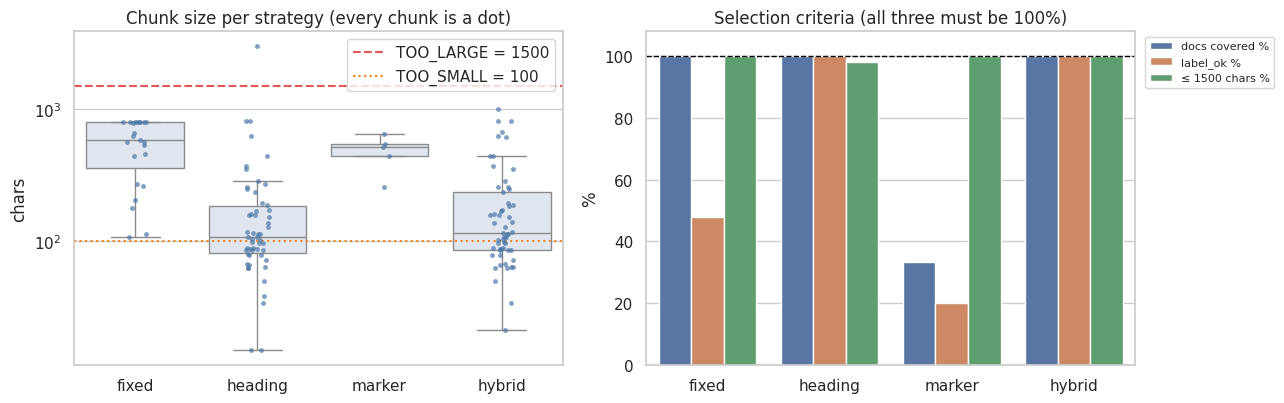

In [8]:
# ==== Compare the strategies on all documents ================================
RESULTS = {s: {name: fn(d["meta"], d["body"]) for name, d in DOCS.items()} for s, fn in STRATEGIES.items()}
size_rows, strat_rows = [], []
for s, per_doc in RESULTS.items():
    chunks = [c for cs in per_doc.values() for c in cs]
    sizes = [len(c["text"]) for c in chunks]
    size_rows += [{"strategy": s, "chars": n} for n in sizes]
    strat_rows.append({
        "strategy": s, "chunks": len(chunks),
        "docs covered %": round(100 * sum(bool(cs) for cs in per_doc.values()) / len(per_doc), 1),
        "median chars": int(statistics.median(sizes)) if sizes else 0, "max chars": max(sizes, default=0),
        f"< {TOO_SMALL}": sum(n < TOO_SMALL for n in sizes), f"> {TOO_LARGE}": sum(n > TOO_LARGE for n in sizes),
        "label_ok %": round(100 * np.mean([label_ok(c) for c in chunks]), 1) if chunks else 0.0,
        "with section %": round(100 * np.mean([c["section"] is not None for c in chunks]), 1) if chunks else 0.0,
        "with page %": round(100 * np.mean([c["page"] is not None for c in chunks]), 1) if chunks else 0.0,
    })
STRAT_DF = pd.DataFrame(strat_rows).set_index("strategy")
display(STRAT_DF)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
sizes_df = pd.DataFrame(size_rows)
sns.boxplot(data=sizes_df, x="strategy", y="chars", ax=axes[0], color="#DDE6F2", showfliers=False)
sns.stripplot(data=sizes_df, x="strategy", y="chars", ax=axes[0], size=3.5, alpha=0.7, color="#4C78A8")
axes[0].axhline(TOO_LARGE, color="#E45756", ls="--", label=f"TOO_LARGE = {TOO_LARGE}")
axes[0].axhline(TOO_SMALL, color="#F58518", ls=":", label=f"TOO_SMALL = {TOO_SMALL}")
axes[0].set(yscale="log", title="Chunk size per strategy (every chunk is a dot)", xlabel="")
axes[0].legend(loc="upper right")
checks = STRAT_DF[["docs covered %", "label_ok %"]].copy()
checks[f"≤ {TOO_LARGE} chars %"] = 100 * (1 - STRAT_DF[f"> {TOO_LARGE}"] / STRAT_DF["chunks"].clip(lower=1))
checks = checks.reset_index().melt("strategy", var_name="check", value_name="%")
sns.barplot(data=checks, x="strategy", y="%", hue="check", ax=axes[1])
axes[1].axhline(100, color="black", ls="--", lw=1)
axes[1].set(title="Selection criteria (all three must be 100%)", ylim=(0, 108), xlabel="")
axes[1].legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
plt.tight_layout()
plt.show()

### Reading the figure — chunking strategies

The comparison figure has two panels. Together they are why **hybrid** is the only strategy that passes.

**Left — chunk size.** Each dot is one chunk (log scale; the box hides extreme outliers). The orange dotted line is the reported lower bound (`TOO_SMALL` = 100 characters) and the red dashed line is the hard cap (`TOO_LARGE` = 1,500).

- **fixed** sits entirely between the two lines (median 579, max 800): overlapping 800-character windows cannot exceed the cap, but they also ignore headings.
- **heading** is mostly short (median 107) because each section becomes its own chunk, but one chunk — the software-catalog spreadsheet — reaches 2,979 characters and crosses the red line.
- **marker** is a thin cloud of only 5 chunks, all inside the band. Most documents have no page or sheet marker, so this strategy barely produces points to plot.
- **hybrid** is short as well (median 115) and its longest chunk is 1,005 characters, under the cap. The dots below 100 are complete one-line sections (a single rule), not empty headings.

**Right — selection criteria.** A strategy is eligible only when all three bars reach the dashed line at 100%: every document yields at least one chunk, every chunk stays inside one section (`label_ok`), and no chunk exceeds 1,500 characters.

- **fixed** covers every document and respects the size cap, but only about 48% of its windows stay inside a single section — they cut across headings.
- **heading** is at 100% on coverage and section integrity, and fails only the size bar (one chunk above 1,500).
- **marker** fails coverage (about 33% of documents) and section integrity (20%).
- **hybrid** is the only strategy with all three bars at 100%. That is the chunker kept for the corpus: 57 chunks, 84% labelled with a section and 33% with a page.


In [9]:
# ==== Chunking — results =====================================================
passing = STRAT_DF[(STRAT_DF["docs covered %"] == 100) & (STRAT_DF[f"> {TOO_LARGE}"] == 0) & (STRAT_DF["label_ok %"] == 100)]
CHOSEN = passing.sort_values(["with section %", f"< {TOO_SMALL}"], ascending=[False, True]).index[0]


def weakness(s: str) -> str:
    """Which selection criteria a strategy misses, with the documents responsible."""
    per_doc, r, out = RESULTS[s], STRAT_DF.loc[s], []
    if r["docs covered %"] < 100:
        out.append(f"produces no chunks for {sum(not cs for cs in per_doc.values())} of {len(per_doc)} documents")
    big = sorted({n for n, cs in per_doc.items() if any(len(c["text"]) > TOO_LARGE for c in cs)})
    if big:
        out.append(f"leaves {int(r[f'> {TOO_LARGE}'])} chunk(s) above {TOO_LARGE} chars (max {int(r['max chars'])}, in "
                   + ", ".join(f"`{n}`" for n in big) + ")")
    if r["label_ok %"] < 100:
        out.append(f"only {r['label_ok %']:.0f}% of chunks stay inside one section")
    return "; ".join(out) or "meets all criteria but has fewer section labels"


chosen_chunks = [c for cs in RESULTS[CHOSEN].values() for c in cs]
short = [c for c in chosen_chunks if len(c["text"]) < TOO_SMALL]
short_with_body = sum(len("\n".join(dropwhile(_HEADING_LINE.match, c["text"].splitlines())).strip()) >= FRAGMENT_BODY_CHARS
                      for c in short)
c = STRAT_DF.loc[CHOSEN]
show_md(
    "\n".join(f"- **{s}** {weakness(s)}." for s in STRAT_DF.index if s != CHOSEN)
    + f"\n- **{CHOSEN}** "
    + ("is the only strategy that meets all three criteria" if len(passing) == 1 else
       f"meets all three criteria (as do {', '.join(x for x in passing.index if x != CHOSEN)}) and has the most section labels")
    + f": {int(c['chunks'])} chunks, median {int(c['median chars'])} chars, max {int(c['max chars'])}, "
    f"{c['with section %']:.0f}% labelled with a section, {c['with page %']:.0f}% with a page.\n"
    f"- {short_with_body} of its {len(short)} chunks under {TOO_SMALL} chars still carry ≥ {FRAGMENT_BODY_CHARS} chars of body "
    "text: they are complete short sections (e.g. a one-line rule), not empty headings, so the lower bound is reported, "
    "not enforced.\n\n"
    f"**→ The corpus uses `{CHOSEN}` chunking.**"
)
REAL_CHUNKS = [ch for name in RAW_SHA256 for ch in RESULTS[CHOSEN][name]]

- **fixed** only 48% of chunks stay inside one section.
- **heading** leaves 1 chunk(s) above 1500 chars (max 2979, in `Approved_Software_Catalog.xlsx`).
- **marker** produces no chunks for 10 of 15 documents; only 20% of chunks stay inside one section.
- **hybrid** is the only strategy that meets all three criteria: 57 chunks, median 115 chars, max 1005, 84% labelled with a section, 33% with a page.
- 22 of its 22 chunks under 100 chars still carry ≥ 20 chars of body text: they are complete short sections (e.g. a one-line rule), not empty headings, so the lower bound is reported, not enforced.

**→ The corpus uses `hybrid` chunking.**

## 3 · Distractors and the final corpus

With only a few dozen real chunks, almost any search method finds the right passage, so retrieval
methods cannot be told apart. The corpus therefore adds **synthetic distractors**: short passages about
company topics that no evaluation question asks about (parking, gym, cafeteria …), in Hebrew, English
and mixed language. They must make search harder **without** leaking answers — no deny-listed answer
string, and low word overlap (Jaccard ≤ `JACCARD_CAP`) with every real chunk.

In [10]:
# ==== Distractor seeds =======================================================
# 143 short passages about company topics that NO evaluation question asks about.
# One tuple per passage: (topic, language, text). language: he / en / bi (mixed).
DISTRACTOR_SEEDS = [
    ('parking', 'he', "חניית עובדים במגרש הצפוני פתוחה בימים א–ה בין 07:00 ל-19:00. יש להציג תו חניה על השמשה."),
    ('parking', 'he', "אורחים נרשמים בעמדת הקבלה ומקבלים כרטיס חניה זמני ליום אחד בלבד."),
    ('parking', 'he', "אופנועים חונים באזור המסומן בצהוב ליד הכניסה המערבית."),
    ('parking', 'he', "רכב חשמלי: עמדות טעינה בקומה מינוס 1, הזמנה מראש באפליקציית OfficeGo."),
    ('parking', 'he', "חניה בסופי שבוע מותרת רק לצוותי תורנות עם אישור מראש ממנהל המתקן."),
    ('parking', 'en', "Employee parking in the north lot is open Sunday–Thursday, 07:00–19:00. Display the permit on the windshield."),
    ('parking', 'en', "Visitors register at reception and receive a one-day temporary parking card."),
    ('parking', 'en', "Motorcycles park in the yellow-marked zone by the west entrance."),
    ('parking', 'en', "EV chargers are on level −1; reserve a slot in the OfficeGo app."),
    ('parking', 'en', "Weekend parking is limited to on-call staff with facility-manager approval."),
    ('dress', 'he', "קוד לבוש במשרד: לבוש עסקי-קז'ואל בימי א–ד. ביום חמישי מותר לבוש חופשי ללא כיתובים פוגעניים."),
    ('dress', 'he', "בפגישות עם לקוחות חובה חולצה מכופתרת או מקבילה מסודרת."),
    ('dress', 'he', "נעלי ספורט מותרות רק באזור כושר ובמעברים אליו."),
    ('dress', 'he', "תגי שם מוצמדים לבגד החיצוני בכל שעות השהייה במשרד."),
    ('dress', 'en', "Office dress code is business-casual Sunday–Wednesday. Thursday is casual if slogans stay respectful."),
    ('dress', 'en', "Client meetings require a collared shirt or equivalent neat attire."),
    ('dress', 'en', "Athletic shoes are allowed only in the gym area and routes to it."),
    ('dress', 'en', "Name badges must stay visible on outer clothing while on site."),
    ('cafeteria', 'he', "הקפיטריה פתוחה 08:00–16:00. תפריט חלבי בימי א/ג/ה ובשרי בימי ב/ד."),
    ('cafeteria', 'he', "הזמנת ארוחות מראש עד 09:30 באפליקציית CafeBook."),
    ('cafeteria', 'he', "מיקרוגלים בחדר האוכל הקטן בקומה 2 לשימוש חופשי עם ניקוי אחרי השימוש."),
    ('cafeteria', 'he', "אלרגנים מסומנים על כל מנה; שאלות לצוות המטבח בדלפק."),
    ('cafeteria', 'en', "The cafeteria is open 08:00–16:00. Dairy menu on Sun/Tue/Thu; meat on Mon/Wed."),
    ('cafeteria', 'en', "Pre-order lunch by 09:30 in the CafeBook app."),
    ('cafeteria', 'en', "Microwaves in the floor-2 pantry are free to use; clean after yourself."),
    ('cafeteria', 'en', "Allergens are labeled on every dish; ask kitchen staff at the counter."),
    ('gym', 'he', "חדר הכושר פתוח 06:30–21:00 עם כרטיס עובד. מגבות חד-פעמיות ליד הכניסה."),
    ('gym', 'he', "שיעורי בוקר בימי ג ו-ה בשעה 07:15; הרשמה עד ערב קודם."),
    ('gym', 'he', "נעליים ייעודיות לחדר כושר חובה על המזרנים והמכשירים."),
    ('gym', 'en', "The gym is open 06:30–21:00 with an employee badge. Disposable towels are by the door."),
    ('gym', 'en', "Morning classes run Tuesday and Thursday at 07:15; sign up the night before."),
    ('gym', 'en', "Dedicated gym shoes are required on mats and machines."),
    ('bike', 'he', "מתלה אופניים מקורה ליד הכניסה הדרומית, 40 מקומות. נעילה אישית חובה."),
    ('bike', 'he', "משאבות אוויר וערכת תיקון בסיסית בארון הכתום ליד המתלה."),
    ('bike', 'he', "קורקינטים חשמליים נשמרים רק באזור הטעינה הייעודי בקומת הקרקע."),
    ('bike', 'en', "Covered bike racks by the south entrance hold 40 bikes. Personal locks are required."),
    ('bike', 'en', "Air pumps and a basic repair kit are in the orange cabinet by the racks."),
    ('bike', 'en', "E-scooters may only charge in the ground-floor scooter bay."),
    ('plants', 'he', "צמחי משרד מטופלים על ידי קבלן גינון בימי ב. אין להזיז עציצים ללא תיאום."),
    ('plants', 'he', "השקיית עציצים אישיים באחריות העובד; מגשי ניקוז חובה."),
    ('plants', 'en', "Office plants are serviced by the landscaping vendor on Mondays. Do not move pots without notice."),
    ('plants', 'en', "Personal desk plants are watered by their owners; drip trays are required."),
    ('badges', 'he', "תגי אורח מונפקים בקבלה ומחזירים אותם ביציאה. אובדן תג מדווח מיד."),
    ('badges', 'he', "קבלנים ארוכי טווח מקבלים תג סגול לתקופת החוזה בלבד."),
    ('badges', 'he', "גישה לקומות מעבדה דורשת תג מורחב אחרי הדרכת בטיחות קצרה."),
    ('badges', 'en', "Visitor badges are issued at reception and returned on exit. Report a lost badge immediately."),
    ('badges', 'en', "Long-term contractors receive a purple badge for the contract period only."),
    ('badges', 'en', "Lab floors need an extended badge after a short safety briefing."),
    ('lostfound', 'he', "מציאות ואבדות נשמרות בארון הקבלה למשך 30 יום ואז נתרמות."),
    ('lostfound', 'he', "מפתחות שנמצאו מועברים לאבטחה בקומה 1 תוך שעה."),
    ('lostfound', 'en', "Lost-and-found items stay at reception for 30 days, then are donated."),
    ('lostfound', 'en', "Found keys go to security on floor 1 within an hour."),
    ('rooms', 'he', "הזמנת חדרי ישיבות דרך לוח השנה הארגוני, עד שעתיים ברצף ללא אישור מיוחד."),
    ('rooms', 'he', "חדר 'אורן' מצויד במסך 75 אינץ'; נקה אחרי השימוש."),
    ('rooms', 'he', "ביטול הזמנה לפחות 30 דקות מראש כדי לשחרר את החדר לאחרים."),
    ('rooms', 'he', "שיחות וידאו ארוכות מומלץ לקיים בחדרים אטומים בקומה 3."),
    ('rooms', 'en', "Book meeting rooms in the org calendar for up to two hours without special approval."),
    ('rooms', 'en', "Room Oren has a 75-inch display; tidy the space after use."),
    ('rooms', 'en', "Cancel bookings at least 30 minutes ahead so others can use the room."),
    ('rooms', 'en', "Long video calls should use the sound-isolated rooms on floor 3."),
    ('parking', 'bi', "חניה / Parking: north lot closes at 19:00. Overnight stays need a facility ticket."),
    ('dress', 'bi', "Dress code / קוד לבוש: client days = collared shirt. Thursday casual is OK."),
    ('cafeteria', 'bi', "Cafeteria / קפיטריה: pre-order by 09:30 in CafeBook. Allergens labeled."),
    ('gym', 'bi', "Gym / חדר כושר: badge access 06:30–21:00. Classes Tue/Thu 07:15."),
    ('bike', 'bi', "Bikes / אופניים: 40 covered racks south entrance; lock required."),
    ('plants', 'bi', "Plants / צמחים: vendor waters Mondays; personal pots need drip trays."),
    ('badges', 'bi', "Badges / תגים: visitors return badges at exit; purple = contractors."),
    ('lostfound', 'bi', "Lost & found / אבדות: 30-day hold at reception, then donate."),
    ('rooms', 'bi', "Rooms / חדרים: org calendar booking, max two hours without escalation."),
    ('parking', 'bi', "חניה / Parking: north lot closes at 19:00. Overnight stays need a facility ticket."),
    ('dress', 'bi', "Dress code / קוד לבוש: client days = collared shirt. Thursday casual is OK."),
    ('cafeteria', 'bi', "Cafeteria / קפיטריה: pre-order by 09:30 in CafeBook. Allergens labeled."),
    ('gym', 'bi', "Gym / חדר כושר: badge access 06:30–21:00. Classes Tue/Thu 07:15."),
    ('bike', 'bi', "Bikes / אופניים: 40 covered racks south entrance; lock required."),
    ('plants', 'bi', "Plants / צמחים: vendor waters Mondays; personal pots need drip trays."),
    ('badges', 'bi', "Badges / תגים: visitors return badges at exit; purple = contractors."),
    ('lostfound', 'bi', "Lost & found / אבדות: 30-day hold at reception, then donate."),
    ('rooms', 'bi', "Rooms / חדרים: org calendar booking, max two hours without escalation."),
    ('parking', 'bi', "חניה / Parking: north lot closes at 19:00. Overnight stays need a facility ticket."),
    ('dress', 'bi', "Dress code / קוד לבוש: client days = collared shirt. Thursday casual is OK."),
    ('cafeteria', 'bi', "Cafeteria / קפיטריה: pre-order by 09:30 in CafeBook. Allergens labeled."),
    ('gym', 'bi', "Gym / חדר כושר: badge access 06:30–21:00. Classes Tue/Thu 07:15."),
    ('bike', 'bi', "Bikes / אופניים: 40 covered racks south entrance; lock required."),
    ('plants', 'bi', "Plants / צמחים: vendor waters Mondays; personal pots need drip trays."),
    ('badges', 'bi', "Badges / תגים: visitors return badges at exit; purple = contractors."),
    ('lostfound', 'bi', "Lost & found / אבדות: 30-day hold at reception, then donate."),
    ('rooms', 'bi', "Rooms / חדרים: org calendar booking, max two hours without escalation."),
    ('parking', 'bi', "חניה / Parking: north lot closes at 19:00. Overnight stays need a facility ticket."),
    ('dress', 'bi', "Dress code / קוד לבוש: client days = collared shirt. Thursday casual is OK."),
    ('cafeteria', 'bi', "Cafeteria / קפיטריה: pre-order by 09:30 in CafeBook. Allergens labeled."),
    ('gym', 'bi', "Gym / חדר כושר: badge access 06:30–21:00. Classes Tue/Thu 07:15."),
    ('bike', 'bi', "Bikes / אופניים: 40 covered racks south entrance; lock required."),
    ('plants', 'bi', "Plants / צמחים: vendor waters Mondays; personal pots need drip trays."),
    ('badges', 'bi', "Badges / תגים: visitors return badges at exit; purple = contractors."),
    ('lostfound', 'bi', "Lost & found / אבדות: 30-day hold at reception, then donate."),
    ('rooms', 'bi', "Rooms / חדרים: org calendar booking, max two hours without escalation."),
    ('parking', 'bi', "חניה / Parking: north lot closes at 19:00. Overnight stays need a facility ticket."),
    ('dress', 'bi', "Dress code / קוד לבוש: client days = collared shirt. Thursday casual is OK."),
    ('cafeteria', 'bi', "Cafeteria / קפיטריה: pre-order by 09:30 in CafeBook. Allergens labeled."),
    ('gym', 'bi', "Gym / חדר כושר: badge access 06:30–21:00. Classes Tue/Thu 07:15."),
    ('bike', 'bi', "Bikes / אופניים: 40 covered racks south entrance; lock required."),
    ('plants', 'bi', "Plants / צמחים: vendor waters Mondays; personal pots need drip trays."),
    ('badges', 'bi', "Badges / תגים: visitors return badges at exit; purple = contractors."),
    ('lostfound', 'bi', "Lost & found / אבדות: 30-day hold at reception, then donate."),
    ('rooms', 'bi', "Rooms / חדרים: org calendar booking, max two hours without escalation."),
    ('parking', 'bi', "חניה / Parking: north lot closes at 19:00. Overnight stays need a facility ticket."),
    ('dress', 'bi', "Dress code / קוד לבוש: client days = collared shirt. Thursday casual is OK."),
    ('cafeteria', 'bi', "Cafeteria / קפיטריה: pre-order by 09:30 in CafeBook. Allergens labeled."),
    ('gym', 'bi', "Gym / חדר כושר: badge access 06:30–21:00. Classes Tue/Thu 07:15."),
    ('bike', 'bi', "Bikes / אופניים: 40 covered racks south entrance; lock required."),
    ('plants', 'bi', "Plants / צמחים: vendor waters Mondays; personal pots need drip trays."),
    ('badges', 'bi', "Badges / תגים: visitors return badges at exit; purple = contractors."),
    ('lostfound', 'bi', "Lost & found / אבדות: 30-day hold at reception, then donate."),
    ('rooms', 'bi', "Rooms / חדרים: org calendar booking, max two hours without escalation."),
    ('parking', 'bi', "חניה / Parking: north lot closes at 19:00. Overnight stays need a facility ticket."),
    ('dress', 'bi', "Dress code / קוד לבוש: client days = collared shirt. Thursday casual is OK."),
    ('cafeteria', 'bi', "Cafeteria / קפיטריה: pre-order by 09:30 in CafeBook. Allergens labeled."),
    ('gym', 'bi', "Gym / חדר כושר: badge access 06:30–21:00. Classes Tue/Thu 07:15."),
    ('bike', 'bi', "Bikes / אופניים: 40 covered racks south entrance; lock required."),
    ('plants', 'bi', "Plants / צמחים: vendor waters Mondays; personal pots need drip trays."),
    ('badges', 'bi', "Badges / תגים: visitors return badges at exit; purple = contractors."),
    ('lostfound', 'bi', "Lost & found / אבדות: 30-day hold at reception, then donate."),
    ('rooms', 'bi', "Rooms / חדרים: org calendar booking, max two hours without escalation."),
    ('parking', 'bi', "חניה / Parking: north lot closes at 19:00. Overnight stays need a facility ticket."),
    ('dress', 'bi', "Dress code / קוד לבוש: client days = collared shirt. Thursday casual is OK."),
    ('cafeteria', 'bi', "Cafeteria / קפיטריה: pre-order by 09:30 in CafeBook. Allergens labeled."),
    ('gym', 'bi', "Gym / חדר כושר: badge access 06:30–21:00. Classes Tue/Thu 07:15."),
    ('bike', 'bi', "Bikes / אופניים: 40 covered racks south entrance; lock required."),
    ('plants', 'bi', "Plants / צמחים: vendor waters Mondays; personal pots need drip trays."),
    ('badges', 'bi', "Badges / תגים: visitors return badges at exit; purple = contractors."),
    ('lostfound', 'bi', "Lost & found / אבדות: 30-day hold at reception, then donate."),
    ('rooms', 'bi', "Rooms / חדרים: org calendar booking, max two hours without escalation."),
    ('parking', 'bi', "חניה / Parking: north lot closes at 19:00. Overnight stays need a facility ticket."),
    ('dress', 'bi', "Dress code / קוד לבוש: client days = collared shirt. Thursday casual is OK."),
    ('cafeteria', 'bi', "Cafeteria / קפיטריה: pre-order by 09:30 in CafeBook. Allergens labeled."),
    ('gym', 'bi', "Gym / חדר כושר: badge access 06:30–21:00. Classes Tue/Thu 07:15."),
    ('bike', 'bi', "Bikes / אופניים: 40 covered racks south entrance; lock required."),
    ('plants', 'bi', "Plants / צמחים: vendor waters Mondays; personal pots need drip trays."),
    ('badges', 'bi', "Badges / תגים: visitors return badges at exit; purple = contractors."),
    ('lostfound', 'bi', "Lost & found / אבדות: 30-day hold at reception, then donate."),
    ('rooms', 'bi', "Rooms / חדרים: org calendar booking, max two hours without escalation."),
    ('parking', 'bi', "חניה / Parking: north lot closes at 19:00. Overnight stays need a facility ticket."),
    ('dress', 'bi', "Dress code / קוד לבוש: client days = collared shirt. Thursday casual is OK."),
]

# Answer strings (amounts, addresses, product names …) that no distractor may contain.
DENYLIST = [
    "nis 120", "nis 150", "120 ₪", "150 ₪", "1,500", "1500 ₪",
    "1.500", "tovanaconnect", "14 characters", "14 תווים", "authenticator", "chol hamoed",
    "חול המועד", "tovanagpt", "phishing@tovana", "hr@tovana", "travel@tovana", "security@tovana",
    "premium economy", "usd 75", "usd 200", "net 30", "שוטף + 45", "שוטף+45",
    "e-401", "e-503", "e-110", "lt-200", "docker desktop", "github enterprise",
    "ignore all previous", "cloudfix-deals", "2 ימים בשבוע", "3 ימים בשבוע", "יום שלישי", "1.5 ימי מחלה",
    "90 ימים", "מכסת החופשה",
]

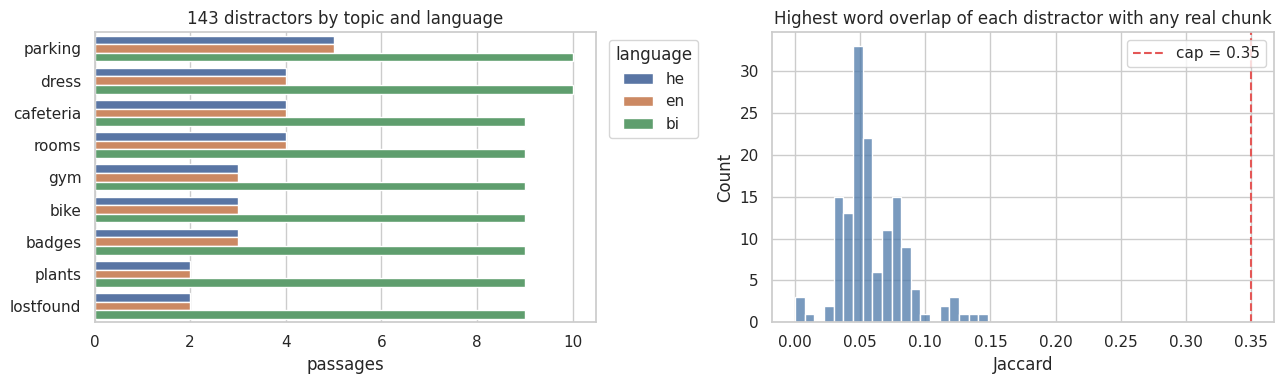

- 143 distractors over 9 topics (bi: 83, he: 30, en: 30).
- Deny-list hits: **0** of 38 answer strings.
- Highest overlap with a real chunk: **0.148** (`syn797486756404-037` vs `195aafee3696-001`), 2.4× below the cap of 0.35 — distractors share style, not content.

In [11]:
# ==== Build the distractors and check for leakage ============================
TOKEN_RE = re.compile(r"[\w\u0590-\u05ff]+", re.UNICODE)


def tokens(text: str) -> set[str]:
    return {t.lower() for t in TOKEN_RE.findall(text)}


def make_distractors(seeds: list[dict]) -> list[dict]:
    """Seed texts -> chunk records with deterministic ids (hash of topic, language and position)."""
    out = []
    for i, s in enumerate(seeds):
        topic, lang, text = s["topic"], s["language_hint"], s["text"]
        title, section = f"Tovana {topic.title()} Guide", f"{topic}-{lang}-{i}"
        out.append({
            "chunk_id": f"syn{sha256(f'syn|{topic}|{lang}|{i}'.encode())[:12]}-{i:03d}", "text": text,
            "strategy": "synthetic", "source_file": f"synthetic/{topic}_{lang}.md", "source_format": "synthetic",
            "title": title, "section": section, "page": None, "context": f"{title} › {section}",
            "doc_id": f"syn-{topic}-{lang}", "char_count": len(text),
            "source_sha256": sha256(f"{topic}|{lang}|{i}".encode()), "topic": topic, "language_hint": lang,
        })
    return out


DISTRACTORS = make_distractors([{"topic": t, "language_hint": l, "text": x} for t, l, x in DISTRACTOR_SEEDS])
deny = [d.lower() for d in DENYLIST]
deny_hits = [(d["chunk_id"], bad) for d in DISTRACTORS for bad in deny if bad in d["text"].lower()]
real_tok = [(c["chunk_id"], tokens(c["text"])) for c in REAL_CHUNKS]
overlaps = []
for d in DISTRACTORS:
    dt = tokens(d["text"])
    jac, rid = max((len(dt & rt) / len(dt | rt) if dt | rt else 0.0, rid) for rid, rt in real_tok)
    overlaps.append({"distractor": d["chunk_id"], "topic": d["topic"], "language": d["language_hint"],
                     "max Jaccard vs real": jac, "closest real chunk": rid})
OVERLAP_DF = pd.DataFrame(overlaps)
MAX_JACCARD = float(OVERLAP_DF["max Jaccard vs real"].max())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
order = OVERLAP_DF["topic"].value_counts().index
sns.countplot(data=OVERLAP_DF, y="topic", hue="language", order=order, ax=axes[0])
axes[0].set(title=f"{len(DISTRACTORS)} distractors by topic and language", xlabel="passages", ylabel="")
axes[0].legend(title="language", loc="upper left", bbox_to_anchor=(1.01, 1))
sns.histplot(OVERLAP_DF["max Jaccard vs real"], bins=20, ax=axes[1], color="#4C78A8")
axes[1].axvline(JACCARD_CAP, color="#E45756", ls="--", label=f"cap = {JACCARD_CAP}")
axes[1].set(title="Highest word overlap of each distractor with any real chunk", xlabel="Jaccard")
axes[1].legend(loc="upper right")
plt.tight_layout()
plt.show()
worst = OVERLAP_DF.loc[OVERLAP_DF["max Jaccard vs real"].idxmax()]
show_md(
    f"- {len(DISTRACTORS)} distractors over {OVERLAP_DF['topic'].nunique()} topics "
    f"({', '.join(f'{k}: {v}' for k, v in OVERLAP_DF['language'].value_counts().items())}).\n"
    f"- Deny-list hits: **{len(deny_hits)}** of {len(DENYLIST)} answer strings.\n"
    f"- Highest overlap with a real chunk: **{MAX_JACCARD:.3f}** (`{worst['distractor']}` vs `{worst['closest real chunk']}`), "
    f"{JACCARD_CAP / max(MAX_JACCARD, 1e-9):.1f}× below the cap of {JACCARD_CAP} — distractors share style, not content."
)

### Reading the figure — distractors

**Left — topics and languages.** How the distractors are spread over topics and languages (`he`, `en`, and `bi`
for mixed Hebrew–English), so retrieval is stressed in every language.

**Right — overlap with real chunks.** For each distractor, its highest word overlap (Jaccard) with any real chunk.
Bars far to the left of the red cap line mean the distractors resemble company text in style but do not repeat
its content, so none of them can accidentally contain an answer.

In [12]:
# ==== One mixed-language distractor ==========================================
example = next(d for d in DISTRACTORS if d["language_hint"] == "bi")
overlap = OVERLAP_DF.loc[OVERLAP_DF["distractor"] == example["chunk_id"]].iloc[0]
hits = [bad for cid, bad in deny_hits if cid == example["chunk_id"]]
leakage = (
    "<div style='margin-top:0.7rem;padding-top:0.55rem;border-top:1px dashed #d5dee8;font-size:0.86rem'>"
    f"<b>Leakage check.</b> Deny-list hits: {html.escape(', '.join(hits) if hits else 'none')}. "
    f"Max Jaccard vs a real chunk: <b>{float(overlap['max Jaccard vs real']):.3f}</b> "
    f"(closest: <code>{html.escape(str(overlap['closest real chunk']))}</code>)."
    "</div>"
)
show_md("### Example — one mixed-language distractor")
display(HTML(f"{CAP}The first passage whose language is <code>bi</code> (Hebrew and English in the same chunk), "
             "with every stored field and its leakage result.</p>" + render_chunk(example, leakage=leakage)))


### Example — one mixed-language distractor

In [13]:
# ==== The corpus =============================================================
corpus = sorted(
    [{**c, "char_count": len(c["text"]), "source_sha256": RAW_SHA256[c["source_file"]]} for c in REAL_CHUNKS] + DISTRACTORS,
    key=lambda c: c["chunk_id"])
assert len({c["chunk_id"] for c in corpus}) == len(corpus), "duplicate chunk ids"
CORPUS_BYTES = "".join(json.dumps(c, ensure_ascii=False) + "\n" for c in corpus).encode("utf-8")
Path("outputs").mkdir(exist_ok=True)
Path("outputs/chunks.jsonl").write_bytes(CORPUS_BYTES)

display(pd.DataFrame([
    {"part": "real chunks", "chunks": len(REAL_CHUNKS), "sources": len({c["doc_id"] for c in REAL_CHUNKS})},
    {"part": "distractors", "chunks": len(DISTRACTORS), "sources": len({c["doc_id"] for c in DISTRACTORS})},
    {"part": "corpus", "chunks": len(corpus), "sources": len({c["doc_id"] for c in corpus})},
]))
show_md(
    "## Summary\n"
    f"- **Conversion:** {int((CONV_DF['chars'] > 0).sum())}/{len(CONV_DF)} documents converted to Markdown; "
    f"OCR was needed only for {', '.join(f'`{f}`' for f in ocr_files) or 'none'}.\n"
    f"- **Chunking:** `{CHOSEN}` "
    + ("is the only strategy that " if len(passing) == 1 else "") +
    f"covers every document, respects the {TOO_LARGE}-char cap and keeps every chunk inside one section.\n"
    f"- **Corpus:** {len(REAL_CHUNKS)} real chunks + {len(DISTRACTORS)} distractors = **{len(corpus)} chunks** "
    f"(`outputs/chunks.jsonl`, sha256 `{sha256(CORPUS_BYTES)[:16]}…`). Retrieval on this corpus is evaluated in notebook 01."
)

,part,chunks,sources
0,real chunks,57,15
1,distractors,143,27
2,corpus,200,42


## Summary
- **Conversion:** 15/15 documents converted to Markdown; OCR was needed only for `SCAN_20230215_0931.pdf`.
- **Chunking:** `hybrid` is the only strategy that covers every document, respects the 1500-char cap and keeps every chunk inside one section.
- **Corpus:** 57 real chunks + 143 distractors = **200 chunks** (`outputs/chunks.jsonl`, sha256 `0946af1b8e105a46…`). Retrieval on this corpus is evaluated in notebook 01.

In [14]:
# ==== The corpus, passage by passage =========================================
cards = "".join(
    render_chunk(chunk, n=i, n_total=len(corpus), brief=True) for i, chunk in enumerate(corpus, 1))
show_md("### The corpus, passage by passage")
display(HTML(
    f"{CAP}{len(corpus)} chunks in <code>outputs/chunks.jsonl</code> order "
    f"({len(REAL_CHUNKS)} real, {len(DISTRACTORS)} distractors). "
    "Blue bar: a passage from a company document. Red bar: a synthetic distractor. "
    "The text of every chunk is shown in full.</p>"
    + cards
))


### The corpus, passage by passage